# EDA: Chest X-Ray Pneumonia Dataset

**Dataset:** [Kaggle Chest X-Ray](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) | **Task:** Binary classification (NORMAL vs PNEUMONIA)

In [11]:
import sys
sys.path.append('..')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import defaultdict
import random

from src.config import DATA_DIR, FIGURES_DIR, CLASS_NAMES

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

# Reproducibility
random.seed(42)
np.random.seed(42)

print(f"Data directory: {DATA_DIR}")
print(f"Figures directory: {FIGURES_DIR}")

Data directory: /Users/richard/Desktop/resume-ml/notebooks/../data/raw
Figures directory: /Users/richard/Desktop/resume-ml/notebooks/../outputs/figures


## 1. Class Distribution

In [2]:
def count_images(data_dir: Path) -> dict:
    """Count images in each split and class."""
    counts = {}
    for split in ['train', 'val', 'test']:
        split_dir = data_dir / split
        if split_dir.exists():
            counts[split] = {}
            for class_name in CLASS_NAMES:
                class_dir = split_dir / class_name
                if class_dir.exists():
                    counts[split][class_name] = len(list(class_dir.glob('*.jpeg')))
                else:
                    counts[split][class_name] = 0
    return counts

# Count images
image_counts = count_images(DATA_DIR)

# Create DataFrame for visualization
df_counts = pd.DataFrame(image_counts).T
df_counts['Total'] = df_counts.sum(axis=1)
df_counts.loc['Total'] = df_counts.sum()

print("=" * 50)
print("DATASET DISTRIBUTION")
print("=" * 50)
print(df_counts)
print("\n")

# Calculate class imbalance ratio
train_normal = image_counts['train']['NORMAL']
train_pneumonia = image_counts['train']['PNEUMONIA']
imbalance_ratio = train_pneumonia / train_normal

print(f"Class Imbalance Ratio (PNEUMONIA:NORMAL): {imbalance_ratio:.2f}:1")
print(f"PNEUMONIA represents {train_pneumonia/(train_normal+train_pneumonia)*100:.1f}% of training data")

DATASET DISTRIBUTION
       NORMAL  PNEUMONIA  Total
train    1341       3875   5216
val         8          8     16
test      234        390    624
Total    1583       4273   5856


Class Imbalance Ratio (PNEUMONIA:NORMAL): 2.89:1
PNEUMONIA represents 74.3% of training data


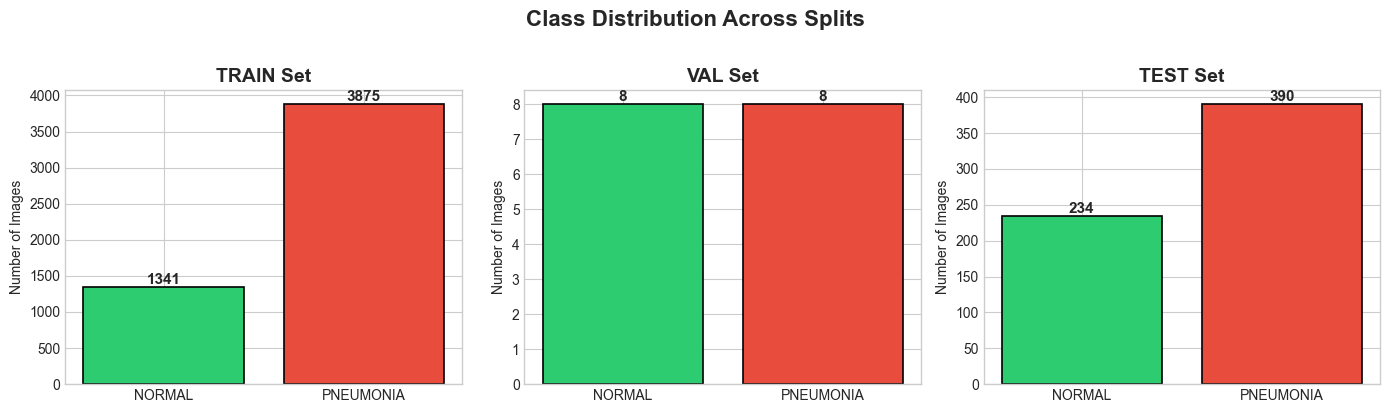


Figure saved to: /Users/richard/Desktop/resume-ml/notebooks/../outputs/figures/class_distribution.png


In [13]:
# Visualize class distribution
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

splits = ['train', 'val', 'test']
colors = ['#2ecc71', '#e74c3c']  # Green for NORMAL, Red for PNEUMONIA

for idx, split in enumerate(splits):
    counts = [image_counts[split]['NORMAL'], image_counts[split]['PNEUMONIA']]
    bars = axes[idx].bar(CLASS_NAMES, counts, color=colors, edgecolor='black', linewidth=1.2)
    axes[idx].set_title(f'{split.upper()} Set', fontsize=14, fontweight='bold')
    axes[idx].set_ylabel('Number of Images')
    
    # Add count labels on bars
    for bar, count in zip(bars, counts):
        axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height(), 
                       str(count), ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.suptitle('Class Distribution Across Splits', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

# Save figure
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / 'class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nFigure saved to: {FIGURES_DIR / 'class_distribution.png'}")

## 2. Sample Images

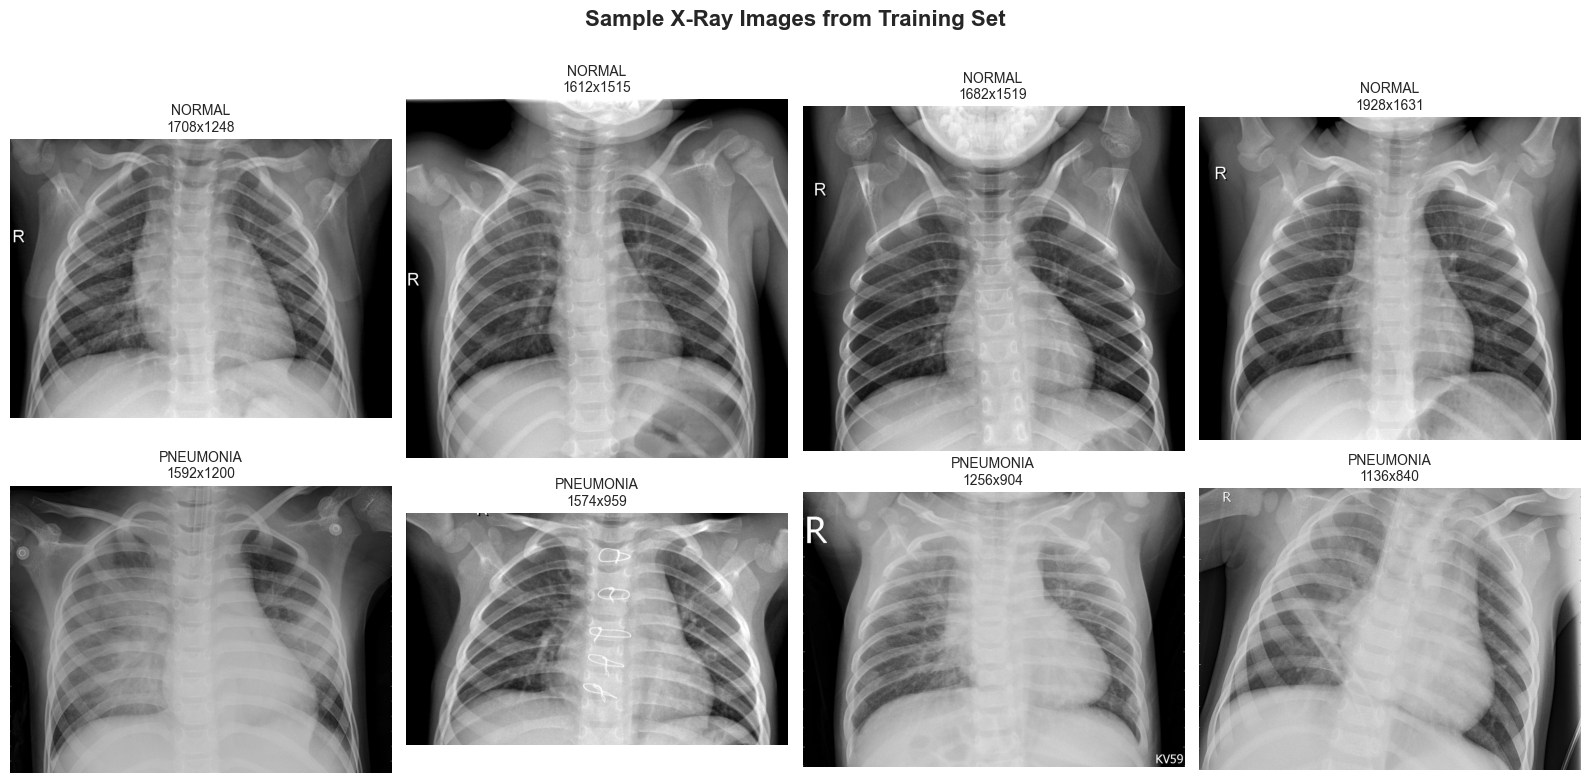

In [4]:
def load_random_images(data_dir: Path, split: str, class_name: str, n: int = 4) -> list:
    """Load n random images from a specific split and class."""
    class_dir = data_dir / split / class_name
    image_files = list(class_dir.glob('*.jpeg'))
    selected = random.sample(image_files, min(n, len(image_files)))
    return [(f.name, Image.open(f)) for f in selected]

# Display sample images from training set
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for row, class_name in enumerate(CLASS_NAMES):
    samples = load_random_images(DATA_DIR, 'train', class_name, n=4)
    for col, (filename, img) in enumerate(samples):
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(f'{class_name}\n{img.size[0]}x{img.size[1]}', fontsize=10)
        axes[row, col].axis('off')

plt.suptitle('Sample X-Ray Images from Training Set', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Image Sizes

In [5]:
def analyze_image_sizes(data_dir: Path, split: str = 'train', sample_size: int = 500) -> pd.DataFrame:
    """Analyze image sizes from a sample of images."""
    records = []
    
    for class_name in CLASS_NAMES:
        class_dir = data_dir / split / class_name
        image_files = list(class_dir.glob('*.jpeg'))
        
        # Sample if too many images
        if len(image_files) > sample_size:
            image_files = random.sample(image_files, sample_size)
        
        for img_path in image_files:
            with Image.open(img_path) as img:
                records.append({
                    'class': class_name,
                    'width': img.size[0],
                    'height': img.size[1],
                    'aspect_ratio': img.size[0] / img.size[1],
                    'mode': img.mode
                })
    
    return pd.DataFrame(records)

# Analyze training set image sizes
print("Analyzing image sizes (this may take a moment)...")
df_sizes = analyze_image_sizes(DATA_DIR, 'train', sample_size=1000)

print("\n" + "=" * 50)
print("IMAGE SIZE STATISTICS")
print("=" * 50)
print(f"\nSample size: {len(df_sizes)} images")
print(f"\nWidth  - Min: {df_sizes['width'].min()}, Max: {df_sizes['width'].max()}, Mean: {df_sizes['width'].mean():.0f}")
print(f"Height - Min: {df_sizes['height'].min()}, Max: {df_sizes['height'].max()}, Mean: {df_sizes['height'].mean():.0f}")
print(f"\nImage modes: {df_sizes['mode'].unique()}")
print(f"\nAspect ratio - Min: {df_sizes['aspect_ratio'].min():.2f}, Max: {df_sizes['aspect_ratio'].max():.2f}")

Analyzing image sizes (this may take a moment)...

IMAGE SIZE STATISTICS

Sample size: 2000 images

Width  - Min: 399, Max: 2916, Mean: 1437
Height - Min: 138, Max: 2663, Mean: 1104

Image modes: ['L' 'RGB']

Aspect ratio - Min: 0.89, Max: 2.93


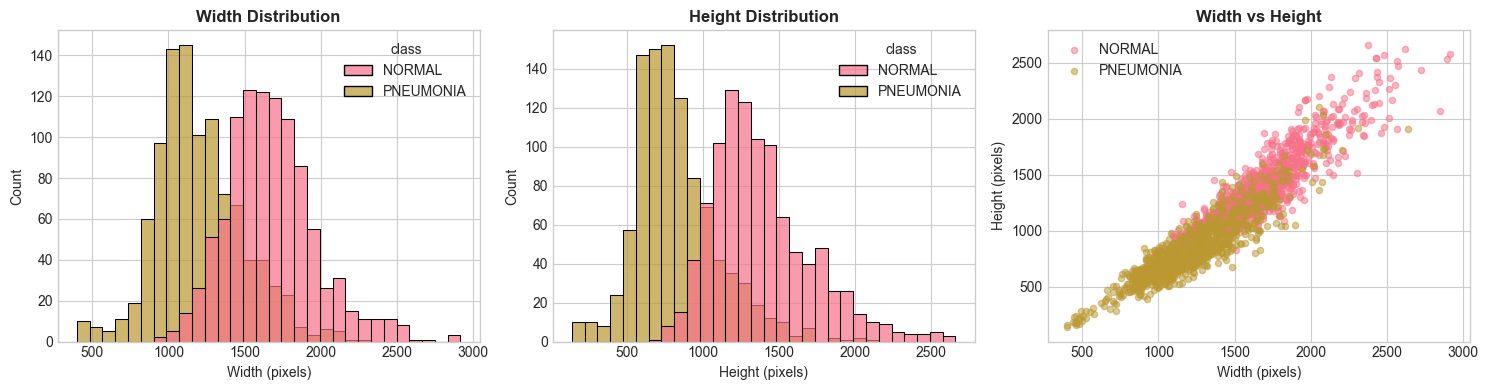

In [14]:
# Visualize size distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Width distribution
sns.histplot(data=df_sizes, x='width', hue='class', bins=30, ax=axes[0], alpha=0.7)
axes[0].set_title('Width Distribution', fontweight='bold')
axes[0].set_xlabel('Width (pixels)')

# Height distribution
sns.histplot(data=df_sizes, x='height', hue='class', bins=30, ax=axes[1], alpha=0.7)
axes[1].set_title('Height Distribution', fontweight='bold')
axes[1].set_xlabel('Height (pixels)')

# Width vs Height scatter
for class_name in CLASS_NAMES:
    subset = df_sizes[df_sizes['class'] == class_name]
    axes[2].scatter(subset['width'], subset['height'], alpha=0.5, label=class_name, s=20)
axes[2].set_title('Width vs Height', fontweight='bold')
axes[2].set_xlabel('Width (pixels)')
axes[2].set_ylabel('Height (pixels)')
axes[2].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'image_sizes.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Pixel Intensity

Computing pixel intensities...


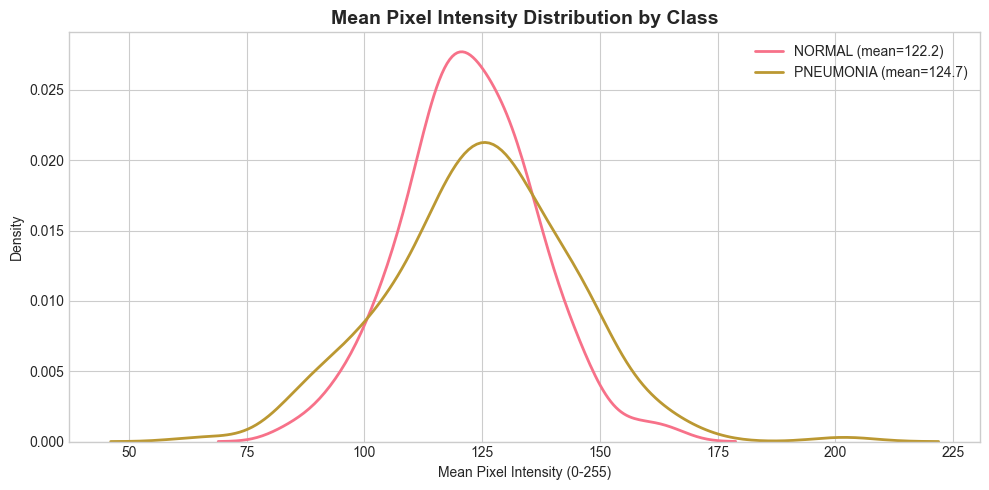


NORMAL mean intensity: 122.2 ± 14.2
PNEUMONIA mean intensity: 124.7 ± 19.3


In [7]:
def compute_mean_intensity(data_dir: Path, split: str, class_name: str, sample_size: int = 100) -> list:
    """Compute mean pixel intensity for a sample of images."""
    class_dir = data_dir / split / class_name
    image_files = list(class_dir.glob('*.jpeg'))
    
    if len(image_files) > sample_size:
        image_files = random.sample(image_files, sample_size)
    
    intensities = []
    for img_path in image_files:
        with Image.open(img_path) as img:
            img_array = np.array(img.convert('L'))  # Convert to grayscale
            intensities.append(img_array.mean())
    
    return intensities

# Compute intensities for each class
print("Computing pixel intensities...")
intensities = {}
for class_name in CLASS_NAMES:
    intensities[class_name] = compute_mean_intensity(DATA_DIR, 'train', class_name, sample_size=200)

# Visualize
fig, ax = plt.subplots(figsize=(10, 5))

for class_name, values in intensities.items():
    sns.kdeplot(values, label=f'{class_name} (mean={np.mean(values):.1f})', ax=ax, linewidth=2)

ax.set_title('Mean Pixel Intensity Distribution by Class', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Pixel Intensity (0-255)')
ax.set_ylabel('Density')
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'pixel_intensity.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nNORMAL mean intensity: {np.mean(intensities['NORMAL']):.1f} ± {np.std(intensities['NORMAL']):.1f}")
print(f"PNEUMONIA mean intensity: {np.mean(intensities['PNEUMONIA']):.1f} ± {np.std(intensities['PNEUMONIA']):.1f}")

## 5. Findings & Issues

### Findings

1. **Dataset Size:** 5,856 total images (5,216 train / 16 val / 624 test)

2. **Class Imbalance:** 2.89:1 ratio (PNEUMONIA:NORMAL). PNEUMONIA represents 74.3% of training data.

3. **Image Variability:** Sizes range from 399x138 to 2916x2663 pixels. Mix of grayscale and RGB formats. Aspect ratios vary from 0.89 to 2.93.

4. **Class-Specific Patterns:** NORMAL images tend to be larger/higher resolution. PNEUMONIA images cluster at smaller dimensions. This suggests images may come from different sources.

5. **Pixel Intensity:** Nearly identical between classes (NORMAL: 122.2, PNEUMONIA: 124.7). Intensity alone is not discriminative.

---

### Issues

1. **Validation set too small** - Only 16 images, not reliable for validation.

2. **Class imbalance** - PNEUMONIA is 3x more common than NORMAL.

3. **Variable image sizes** - All images need resizing for model input.

4. **Mixed image modes** - Some grayscale, some RGB.

5. **Potential shortcut learning** - Different image sources per class could cause model to learn artifacts instead of medical features.

---

**Next:** Phase 3 - Data Preprocessing & Augmentation